# 03. Extensión experimental: la fuga de información

Recreación con datos simulados de Imtiaz et al. (2025), *Computers and Electronics in Agriculture*, 237, 110636.

**Condición experimental modificada:** el esquema de validación. Se comparan cuatro esquemas manteniendo constantes los datos, los modelos y las métricas:

1. **Aleatorio** (16 particiones), equivalente al procedimiento del artículo.
2. **Por bloques** (grilla de 4 × 4 bloques de 97,5 m).
3. **Por bloques con zona de exclusión** de 40 m (igual al alcance de la autocorrelación).
4. **Por parcela** (entrenar con tres parcelas y evaluar en la cuarta).

Además de los tres modelos del artículo, se incluye una **línea base lineal (Ridge)**. Diseño: Sentinel-2, estrategia multivariada, 10 réplicas; en B y D se evalúa también la respuesta interpolada.

## 1. Configuración


In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

RAIZ = Path.cwd().parent
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

from src import config
from src.validacion import ejecutar_extension

sns.set_theme(style="whitegrid", context="notebook")
print("Réplicas:", config.N_REPLICAS_EXTENSION, "| Modelos:", config.MODELOS_EXTENSION)

Réplicas: 10 | Modelos: ['CART', 'RF', 'GTB', 'Ridge']


## 2. Ejecución del experimento: esquemas dentro de cada parcela

Para cada réplica, parcela, esquema, respuesta y modelo se entrena un modelo en cada partición y se predice la parte no vista. Las métricas se calculan con todas las predicciones fuera de muestra. La columna `r2_vs_real` mide el desempeño frente al rendimiento real, aunque el modelo se haya entrenado con el interpolado. Las réplicas se procesan en paralelo y los resultados se guardan en `results/03_extension.csv`.

In [2]:
extension = ejecutar_extension()
print(extension.shape)
extension.head()

(720, 11)


,replica,alcance_m,parcela,esquema,respuesta,modelo,r2,r2_corr,rmse,mae,r2_vs_real
0,0,40.0,A,aleatoria,rendimiento,CART,0.731675,0.745666,5.299964,4.139566,0.731675
1,0,40.0,A,aleatoria,rendimiento,RF,0.862431,0.862607,3.794919,2.986101,0.862431
2,0,40.0,A,aleatoria,rendimiento,GTB,0.833991,0.834796,4.168771,3.241461,0.833991
3,0,40.0,A,aleatoria,rendimiento,Ridge,0.870842,0.870842,3.677086,2.903966,0.870842
4,0,40.0,A,bloques,rendimiento,CART,0.744341,0.767082,5.173364,4.106063,0.744341


**Resultado.** El experimento produjo 720 evaluaciones (10 réplicas × 6 combinaciones de parcela y respuesta × 3 esquemas × 4 modelos) en unos 28 minutos de cálculo en paralelo. Cada fila contiene las métricas calculadas con las predicciones fuera de muestra y, en la columna `r2_vs_real`, el desempeño frente al rendimiento real. Los resultados quedan en `results/03_extension.csv`.

## 3. Brecha de optimismo (medida C1)

Se compara el R² de los tres esquemas dentro de cada parcela. La **brecha de optimismo** es la diferencia entre el R² con validación aleatoria (procedimiento del artículo) y el R² con validación por bloques con zona de exclusión (el esquema más estricto). Se calcula en cada réplica como diferencia pareada y se resume con su media y su intervalo del 95 %. Una brecha cercana a 0 indica ausencia de fuga espacial; una brecha positiva indica que la validación aleatoria sobreestima el desempeño.

esquema                                 aleatoria  bloques  bloques_exclusion
respuesta               parcela modelo                                       
rendimiento             A       CART         0.72     0.71               0.70
                                GTB          0.82     0.82               0.82
                                RF           0.84     0.84               0.84
                                Ridge        0.86     0.85               0.85
                        B       CART         0.42     0.45               0.44
                                GTB          0.65     0.65               0.65
                                RF           0.69     0.69               0.69
                                Ridge        0.72     0.72               0.71
                        C       CART         0.51     0.48               0.48
                                GTB          0.70     0.69               0.70
                                RF           0.73     0.73               0.72
                                Ridge        0.75     0.75               0.75
                        D       CART         0.43     0.43               0.43
                                GTB          0.65     0.64               0.64
                                RF           0.68     0.68               0.68
                                Ridge        0.70     0.70               0.70
rendimiento_interpolado B       CART        -0.92    -1.02              -1.11
                                GTB         -0.18    -0.25              -0.29
                                RF          -0.04    -0.12              -0.16
                                Ridge        0.01    -0.06              -0.11
                        D       CART        -1.04    -1.10              -1.10
                                GTB         -0.24    -0.30              -0.32
                                RF          -0.09    -0.14              -0.17
                                Ridge       -0.02    -0.06              -0.10

media  ic_inf  ic_sup
respuesta               parcela modelo                       
rendimiento             A       CART    0.021  -0.022   0.079
                                GTB    -0.000  -0.016   0.017
                                RF      0.004  -0.002   0.010
                                Ridge   0.002  -0.000   0.004
                        B       CART   -0.016  -0.115   0.068
                                GTB     0.000  -0.028   0.031
                                RF      0.006  -0.010   0.022
                                Ridge   0.002  -0.003   0.007
                        C       CART    0.029  -0.028   0.065
                                GTB    -0.000  -0.029   0.017
                                RF      0.003  -0.004   0.007
                                Ridge   0.002  -0.001   0.006
                        D       CART   -0.001  -0.054   0.075
                                GTB     0.008  -0.024   0.060
                                RF      0.004  -0.004   0.023
                                Ridge   0.004  -0.001   0.007
rendimiento_interpolado B       CART    0.187   0.010   0.380
                                GTB     0.119   0.069   0.167
                                RF      0.113   0.072   0.165
                                Ridge   0.119   0.093   0.154
                        D       CART    0.061  -0.209   0.468
                                GTB     0.075  -0.014   0.166
                                RF      0.081  -0.007   0.147
                                Ridge   0.077   0.033   0.133

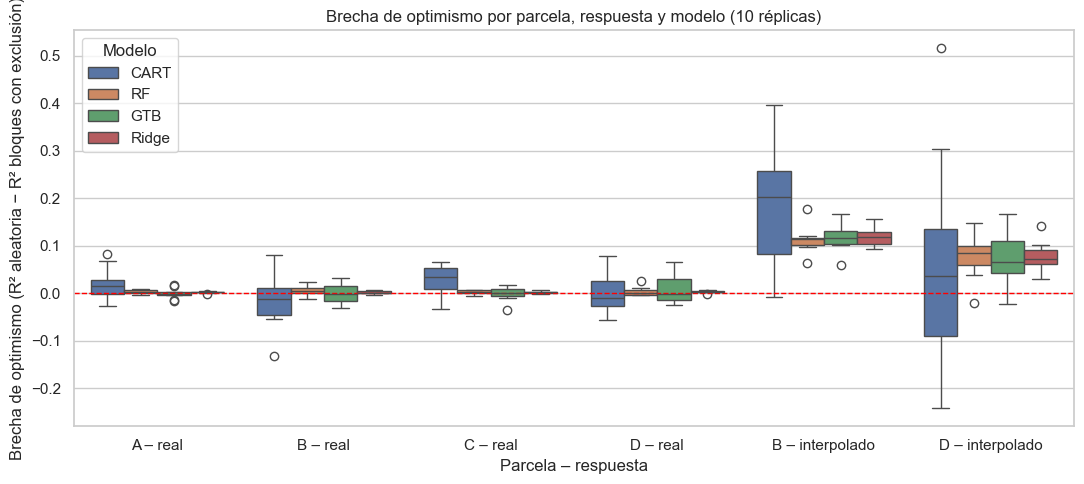

In [3]:
orden_esquemas = ["aleatoria", "bloques", "bloques_exclusion"]

# R² medio por esquema
r2_por_esquema = (extension.groupby(["respuesta", "parcela", "modelo", "esquema"])["r2"]
                  .mean().unstack("esquema")[orden_esquemas])
display(r2_por_esquema.round(2))

# Brecha de optimismo por réplica (diferencia pareada)
ancho = extension.pivot_table(index=["replica", "respuesta", "parcela", "modelo"],
                              columns="esquema", values="r2")
ancho["brecha"] = ancho["aleatoria"] - ancho["bloques_exclusion"]
brecha = ancho["brecha"].reset_index()

resumen_brecha = brecha.groupby(["respuesta", "parcela", "modelo"])["brecha"].agg(
    media="mean",
    ic_inf=lambda s: s.quantile(0.025),
    ic_sup=lambda s: s.quantile(0.975),
)
display(resumen_brecha.round(3))
pd.concat({"r2_por_esquema": r2_por_esquema.reset_index(),
           "brecha": resumen_brecha.reset_index()}).to_csv(
    config.DIR_RESULTADOS / "03_brecha_optimismo.csv")

# Gráfica: brecha por parcela, respuesta y modelo
brecha["caso"] = brecha["parcela"] + " – " + brecha["respuesta"].map(
    {"rendimiento": "real", "rendimiento_interpolado": "interpolado"})
orden_casos = ["A – real", "B – real", "C – real", "D – real", "B – interpolado", "D – interpolado"]
fig, ax = plt.subplots(figsize=(11, 5))
sns.boxplot(data=brecha, x="caso", y="brecha", hue="modelo", order=orden_casos,
            hue_order=config.MODELOS_EXTENSION, ax=ax)
ax.axhline(0, color="red", lw=1, ls="--")
ax.set(xlabel="Parcela – respuesta",
       ylabel="Brecha de optimismo (R² aleatoria − R² bloques con exclusión)",
       title="Brecha de optimismo por parcela, respuesta y modelo (10 réplicas)")
ax.legend(title="Modelo", loc="upper left")
fig.tight_layout()
fig.savefig(config.DIR_FIGURAS / "03_brecha_optimismo.png", dpi=150)
plt.show()

**Resultado.**

*1. Con el rendimiento real no hay fuga espacial.* Los tres esquemas producen prácticamente el mismo R² en las cuatro parcelas. La brecha de optimismo de Ridge, RF y GTB es de 0,000 a 0,008, con intervalos que incluyen el 0; la de CART varía más entre réplicas (−0,016 a 0,029 en promedio), también sin diferencia significativa. Cuando cada punto tiene su propio rendimiento medido y los predictores no contienen información de ubicación, la autocorrelación espacial del rendimiento, por sí sola, no produce fuga.

*2. Con el rendimiento interpolado aparece una fuga clara.* En B, la brecha es de 0,11 a 0,19 y los cuatro intervalos del 95 % excluyen el 0; en D es de 0,06 a 0,08, significativa para Ridge. La validación aleatoria del artículo infla el R² en ~0,1 cuando la respuesta proviene de interpolar 30 mediciones, porque los valores interpolados de puntos vecinos son casi idénticos (sección 7.1 del notebook 01) y quedan a ambos lados de la partición.

*3. La fuga infla, pero no explica por sí sola los resultados del artículo.* Aun con validación aleatoria, el R² frente a la superficie interpolada es cercano a 0 en la simulación, lejos del 0,60–0,69 reportado. Si la interpolación conservara más variabilidad (manchas de mayor tamaño), la misma fuga se sumaría a un R² de partida mayor; esto se pone a prueba en la sensibilidad al alcance.

*4. La línea base lineal es el mejor modelo.* Con el rendimiento real, Ridge obtiene el mayor R² en las

## 4. Validación por parcela (transferencia entre lotes)

Es el esquema más exigente: para cada parcela, el modelo se entrena con las otras tres (~900 puntos) y se evalúa en la parcela excluida, que nunca vio. Responde si un modelo entrenado en unos lotes funciona en un lote o un año distinto. Los modelos del artículo usan los hiperparámetros de la Tabla 3 de la parcela evaluada, y se usa el rendimiento real.

Se compara con el R² de la validación aleatoria dentro de cada parcela (sección 3) y se reporta, además, el **sesgo** (media predicha menos media observada, en t/ha) y el **r²**, que indica si el modelo ordena bien los puntos dentro de la parcela aunque se equivoque en el nivel general.

r2  r2_corr  rmse  sesgo  r2_dentro_parcela  caida_r2
parcela modelo                                                         
A       CART    0.76     0.78  5.05   1.23               0.72     -0.04
        GTB     0.81     0.82  4.47   1.06               0.82      0.01
        RF      0.79     0.81  4.64   1.38               0.84      0.05
        Ridge   0.74     0.85  5.18   0.28               0.86      0.11
B       CART    0.42     0.57  4.70   0.78               0.42      0.00
        GTB     0.60     0.67  3.91   0.59               0.65      0.05
        RF      0.65     0.70  3.67   0.82               0.69      0.05
        Ridge   0.60     0.62  3.90   0.70               0.72      0.12
C       CART    0.21     0.53  4.27  -0.41               0.51      0.30
        GTB     0.54     0.65  3.29  -0.56               0.70      0.16
        RF      0.67     0.73  2.78  -0.47               0.73      0.06
        Ridge   0.42     0.71  3.68   0.53               0.75      0.33
D       CART    0.47     0.55  4.87  -1.42               0.43     -0.04
        GTB     0.56     0.63  4.44  -1.69               0.65      0.09
        RF      0.60     0.67  4.23  -1.63               0.68      0.08
        Ridge   0.39     0.59  5.25  -2.89               0.70      0.32

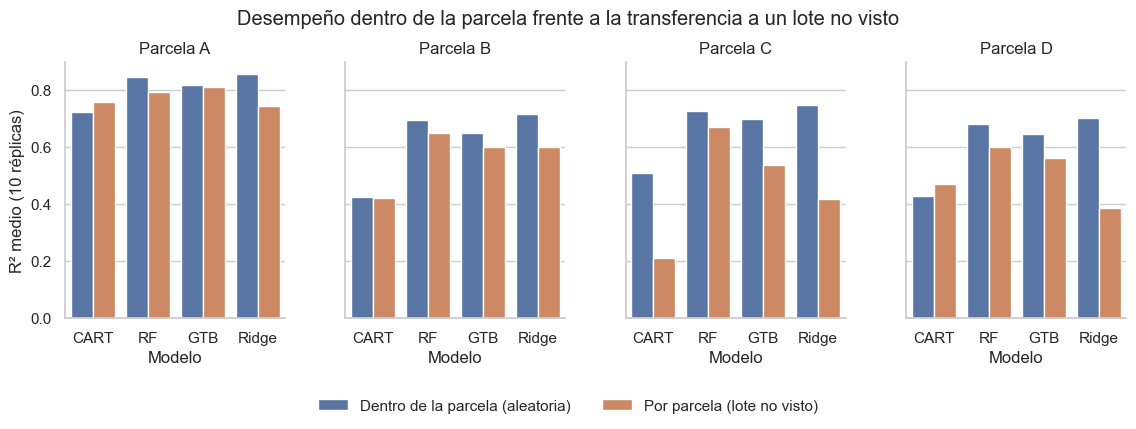

In [4]:
from src.validacion import ejecutar_validacion_por_parcela

por_parcela = ejecutar_validacion_por_parcela()

# R² dentro de cada parcela (validación aleatoria, rendimiento real) para comparar
dentro = (extension[(extension["respuesta"] == "rendimiento") & (extension["esquema"] == "aleatoria")]
          .groupby(["parcela", "modelo"])["r2"].mean().rename("r2_dentro_parcela"))

transferencia = (por_parcela.groupby(["parcela_evaluada", "modelo"])[["r2", "r2_corr", "rmse", "sesgo"]]
                 .mean().rename_axis(["parcela", "modelo"]).join(dentro))
transferencia["caida_r2"] = transferencia["r2_dentro_parcela"] - transferencia["r2"]
display(transferencia.round(2))
transferencia.to_csv(config.DIR_RESULTADOS / "03_transferencia_parcelas.csv")

# Gráfica: R² dentro de la parcela frente a R² al transferir
grafica = transferencia.reset_index().melt(
    id_vars=["parcela", "modelo"], value_vars=["r2_dentro_parcela", "r2"],
    var_name="validacion", value_name="R2")
grafica["validacion"] = grafica["validacion"].map(
    {"r2_dentro_parcela": "Dentro de la parcela (aleatoria)", "r2": "Por parcela (lote no visto)"})
g = sns.catplot(data=grafica, x="modelo", y="R2", hue="validacion", col="parcela", kind="bar",
                order=config.MODELOS_EXTENSION, height=3.6, aspect=0.8, legend_out=False)
for ax in g.axes.flat:
    ax.axhline(0, color="gray", lw=0.8)
g.set_axis_labels("Modelo", "R² medio (10 réplicas)")
g.set_titles("Parcela {col_name}")
sns.move_legend(g, "lower center", bbox_to_anchor=(0.5, -0.12), ncol=2, title=None, frameon=False)
g.figure.suptitle("Desempeño dentro de la parcela frente a la transferencia a un lote no visto", y=1.04)
g.savefig(config.DIR_FIGURAS / "03_transferencia_parcelas.png", dpi=150, bbox_inches="tight")
plt.show()

**Resultado.**

| Modelo | R² dentro de la parcela | R² en lote no visto | Caída del R² |
|---|---|---|---|
| RF | 0,68–0,84 | 0,60–0,79 | 0,05–0,08 |
| GTB | 0,65–0,82 | 0,54–0,81 | 0,01–0,16 |
| Ridge | 0,70–0,86 | 0,39–0,74 | 0,11–0,33 |
| CART | 0,42–0,72 | 0,21–0,76 | −0,04–0,30 |

*1. El mejor modelo depende del esquema de validación.* Dentro de cada parcela gana Ridge; al transferir a un lote no visto, Ridge es el que más cae (hasta 0,33 de R²) y RF es el más robusto (caída de 0,05–0,08).

*2. Ridge falla en el nivel, no en el orden.* Al entrenar con tres parcelas, la recta se ajusta a la nube conjunta, dominada por la diferencia entre parcelas de rendimiento bajo y alto y por la saturación del dosel en B y D. En D subestima en 2,9 t/ha en promedio (R² de 0,39), aunque su r² (0,59) muestra que ordena razonablemente los puntos. RF predice promediando observaciones con predictores similares y no extrapola una recta, lo que lo hace más robusto cuando la relación cambia entre lotes.

*3. Más datos estabilizan a CART.* En A y D, CART obtiene un R² mayor al transferir que dentro de la parcela, porque se entrena con ~900 puntos en lugar de ~280: con más datos, un modelo de alta varianza se vuelve más estable.

*4. Sesgo sistemático entre grupos de parcelas.* Los modelos sobreestiman A y B (+0,3 a +1,4 t/ha) y subestiman D (−1,4 a −2,9 t/ha): transferir entre lotes con niveles de rendimiento distintos introduce errores sistemáticos.

*Lección metodológica.* La validación debe imitar el uso real del modelo. Si un modelo se entrenará con unos lotes o municipios y se aplicará a otros, debe validarse dejando lotes o municipios completos fuera del entrenamiento; una validación aleatoria dentro de los mismos lotes puede elegir un modelo que no se transfiere bien.

## 5. Sensibilidad al alcance de la autocorrelación (medida R6)

Con manchas de rendimiento de 30–50 m, la superficie interpolada desde 30 mediciones (separadas 65 m) casi no conserva información del lote, y los R² del artículo en B y D no se reproducen. Se pone a prueba si se reproducirían con manchas de mayor tamaño. Se repite el experimento con alcances de 30, 50 y 150 m (el de 40 m proviene de la sección 2, réplicas 0 a 4).

Diseño acotado: parcelas B y D, modelos Ridge y RF, esquemas aleatorio y por bloques con zona de exclusión, 5 réplicas. La zona de exclusión se mantiene en 40 m para todos los alcances; con manchas de 150 m, la brecha de optimismo medida es un límite inferior.

r2_real  r2_interpolado  r2_interp_vs_real
alcance_m esquema           modelo                                            
30.0      aleatoria         RF         0.68           -0.08              -0.01
                            Ridge      0.71           -0.02               0.01
          bloques_exclusion RF         0.68           -0.18              -0.01
                            Ridge      0.71           -0.12               0.01
40.0      aleatoria         RF         0.69           -0.07               0.03
                            Ridge      0.71           -0.01               0.06
          bloques_exclusion RF         0.68           -0.17               0.03
                            Ridge      0.71           -0.11               0.05
50.0      aleatoria         RF         0.69           -0.06               0.07
                            Ridge      0.71            0.01               0.10
          bloques_exclusion RF         0.68           -0.15               0.07
                            Ridge      0.71           -0.09               0.09
150.0     aleatoria         RF         0.68            0.08               0.24
                            Ridge      0.70            0.12               0.27
          bloques_exclusion RF         0.66           -0.02               0.22
                            Ridge      0.69            0.02               0.24

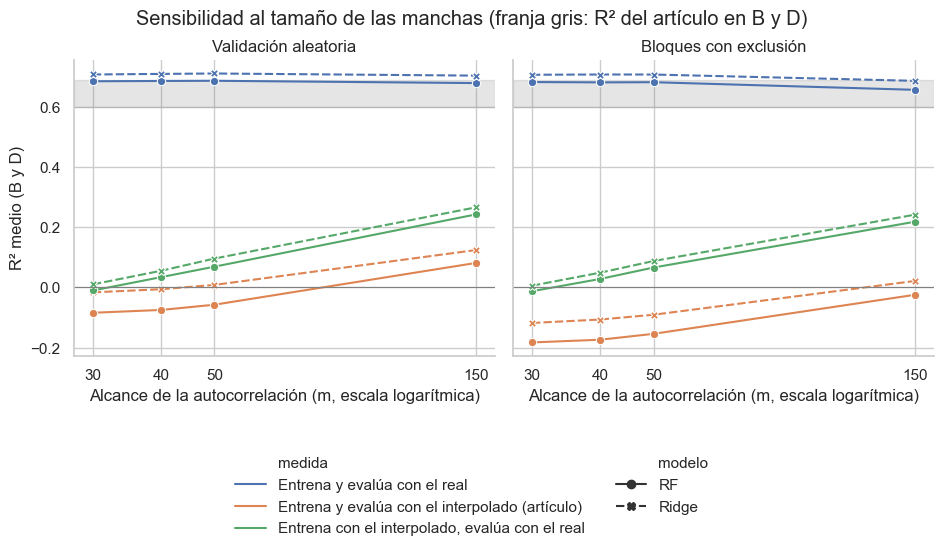

In [5]:
alcances_nuevos = [30.0, 50.0, 150.0]
acotado = dict(n_replicas=5, parcelas=["B", "D"], modelos=["Ridge", "RF"],
               esquemas=["aleatoria", "bloques_exclusion"])

tablas = [ejecutar_extension(alcance_m=a, archivo=f"03_sensibilidad_alcance_{int(a)}.csv", **acotado)
          for a in alcances_nuevos]

# Alcance de 40 m: resultados de la sección 2, con el mismo diseño acotado
base_40 = extension[(extension["replica"] < 5) & extension["parcela"].isin(["B", "D"])
                    & extension["modelo"].isin(["Ridge", "RF"])
                    & extension["esquema"].isin(["aleatoria", "bloques_exclusion"])]
sensibilidad = pd.concat([base_40] + tablas, ignore_index=True)

# Tres medidas por alcance, esquema y modelo
real = sensibilidad[sensibilidad["respuesta"] == "rendimiento"]
interp = sensibilidad[sensibilidad["respuesta"] == "rendimiento_interpolado"]
claves = ["alcance_m", "esquema", "modelo"]
resumen_alcance = pd.concat({
    "r2_real": real.groupby(claves)["r2"].mean(),
    "r2_interpolado": interp.groupby(claves)["r2"].mean(),
    "r2_interp_vs_real": interp.groupby(claves)["r2_vs_real"].mean(),
}, axis=1)
display(resumen_alcance.round(2))
resumen_alcance.to_csv(config.DIR_RESULTADOS / "03_sensibilidad_alcance.csv")

# Gráfica
grafica = resumen_alcance.reset_index().melt(
    id_vars=claves, var_name="medida", value_name="R2")
grafica["medida"] = grafica["medida"].map({
    "r2_real": "Entrena y evalúa con el real",
    "r2_interpolado": "Entrena y evalúa con el interpolado (artículo)",
    "r2_interp_vs_real": "Entrena con el interpolado, evalúa con el real",
})
grafica["esquema"] = grafica["esquema"].map(
    {"aleatoria": "Validación aleatoria", "bloques_exclusion": "Bloques con exclusión"})
g = sns.relplot(data=grafica, x="alcance_m", y="R2", hue="medida", style="modelo",
                col="esquema", kind="line", markers=True, height=4, aspect=1.2,
                facet_kws={"legend_out": False})
for ax in g.axes.flat:
    ax.axhspan(0.60, 0.69, color="gray", alpha=0.2)
    ax.axhline(0, color="gray", lw=0.8)
    ax.set_xscale("log")
    ax.set_xticks([30, 40, 50, 150])
    ax.set_xticklabels(["30", "40", "50", "150"])
    ax.minorticks_off()
g.set_axis_labels("Alcance de la autocorrelación (m, escala logarítmica)", "R² medio (B y D)")
g.set_titles("{col_name}")
sns.move_legend(g, "lower center", bbox_to_anchor=(0.5, -0.32), ncol=2, title=None, frameon=False)
g.figure.suptitle("Sensibilidad al tamaño de las manchas (franja gris: R² del artículo en B y D)", y=1.03)
g.savefig(config.DIR_FIGURAS / "03_sensibilidad_alcance.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Selección de hiperparámetros: fija, con fuga y anidada (hallazgo 12)

Los autores ajustaron los hiperparámetros por ensayo y error, mirando el desempeño en el mismo conjunto con el que reportaron los resultados. Se comparan tres formas de selección con una validación cruzada externa aleatoria de 5 particiones:

- **Fija:** hiperparámetros del artículo (Tabla 3); en Ridge, alpha = 1.
- **Con fuga:** en cada partición externa se prueban todas las combinaciones de la rejilla y se conserva la que mejor desempeño obtiene en el propio conjunto de prueba, como hicieron los autores.
- **Anidada:** la combinación se elige con una validación cruzada interna de 5 particiones, solo sobre el entrenamiento; el conjunto de prueba se usa una sola vez.

La diferencia entre "con fuga" y "anidada" mide el optimismo por selección. Diseño: parcelas A y C (rendimiento real, donde no hay fuga espacial), Ridge (5 valores de alpha) y RF (8 combinaciones dentro del rango de la Tabla 3), 5 réplicas.

5 réplicas terminadas en 1.4 min


seleccion        fija  con_fuga  anidada
parcela modelo                          
A       RF      0.854     0.861    0.853
        Ridge   0.868     0.875    0.872
C       RF      0.735     0.743    0.733
        Ridge   0.762     0.768    0.759

seleccion      optimismo               ganancia_ajuste              
                    mean    min    max            mean    min    max
parcela modelo                                                      
A       RF         0.009  0.003  0.019          -0.001 -0.003  0.001
        Ridge      0.003  0.001  0.006           0.003 -0.000  0.010
C       RF         0.010  0.006  0.013          -0.002 -0.004 -0.000
        Ridge      0.009  0.002  0.020          -0.002 -0.007  0.005

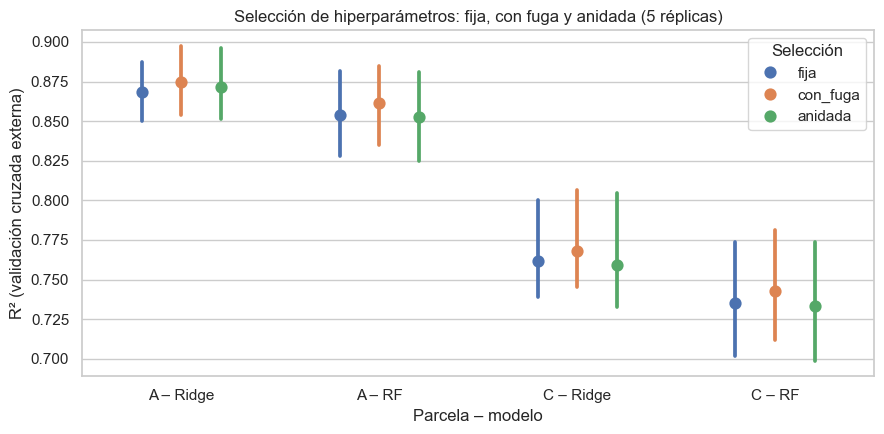

In [6]:
from src.validacion import ejecutar_seleccion_hiperparametros

seleccion = ejecutar_seleccion_hiperparametros()

orden_seleccion = ["fija", "con_fuga", "anidada"]
r2_seleccion = (seleccion.groupby(["parcela", "modelo", "seleccion"])["r2"]
                .mean().unstack("seleccion")[orden_seleccion])
display(r2_seleccion.round(3))

# Optimismo por selección: con fuga − anidada, por réplica
ancho = seleccion.pivot_table(index=["replica", "parcela", "modelo"], columns="seleccion", values="r2")
ancho["optimismo"] = ancho["con_fuga"] - ancho["anidada"]
ancho["ganancia_ajuste"] = ancho["anidada"] - ancho["fija"]
resumen_seleccion = ancho.groupby(["parcela", "modelo"])[["optimismo", "ganancia_ajuste"]].agg(["mean", "min", "max"])
display(resumen_seleccion.round(3))
pd.concat({"r2": r2_seleccion.reset_index(),
           "optimismo": resumen_seleccion.reset_index()}).to_csv(
    config.DIR_RESULTADOS / "03_resumen_seleccion.csv")

# Gráfica
fig, ax = plt.subplots(figsize=(9, 4.5))
seleccion["caso"] = seleccion["parcela"] + " – " + seleccion["modelo"]
sns.pointplot(data=seleccion, x="caso", y="r2", hue="seleccion", hue_order=orden_seleccion,
              errorbar=("pi", 95), dodge=0.4, linestyle="none", ax=ax)
ax.set(xlabel="Parcela – modelo", ylabel="R² (validación cruzada externa)",
       title="Selección de hiperparámetros: fija, con fuga y anidada (5 réplicas)")
ax.legend(title="Selección")
fig.tight_layout()
fig.savefig(config.DIR_FIGURAS / "03_seleccion_hiperparametros.png", dpi=150)
plt.show()

**Resultado.**

| Parcela – modelo | Fija | Con fuga | Anidada | Optimismo (con fuga − anidada) |
|---|---|---|---|---|
| A – Ridge | 0,868 | 0,875 | 0,872 | 0,003 (0,001 a 0,006) |
| A – RF | 0,854 | 0,861 | 0,853 | 0,009 (0,003 a 0,019) |
| C – Ridge | 0,762 | 0,768 | 0,759 | 0,009 (0,002 a 0,020) |
| C – RF | 0,735 | 0,743 | 0,733 | 0,010 (0,006 a 0,013) |

*1. La selección con fuga infla el desempeño de forma sistemática.* El optimismo es positivo en todas las réplicas, parcelas y modelos: elegir la configuración mirando el conjunto de prueba siempre produce un R² mayor que el que se obtendría con datos nuevos.

*2. El efecto es pequeño en este diseño (0,003–0,010).* Las rejillas son cortas (5 y 8 combinaciones) y los modelos estables. El optimismo crece con el número de combinaciones probadas y con la variabilidad del conjunto de prueba; en el artículo se ajustaron 16 combinaciones de parcela, sensor y modelo por ensayo y error, con conjuntos de prueba de 90 puntos, condiciones que favorecen un optimismo mayor.

*3. El ajuste no mejora el desempeño.* La selección anidada rinde igual que la fija (diferencias de −0,002 a +0,003): los valores de la Tabla 3 ya están cerca del óptimo. El ajuste manual del artículo no aporta desempeño real y sí introduce riesgo de fuga.

*Hallazgo 12 confirmado y dimensionado:* la fuga por selección existe y siempre va en la misma dirección, pero en este diseño es la de menor magnitud entre las fuentes analizadas.

## 7. Síntesis de la extensión experimental

**Condición modificada:** el esquema de validación (aleatorio, por bloques, por bloques con zona de exclusión y por parcela), con datos, modelos y métricas constantes. Como complementos, se agregaron una línea base lineal, la sensibilidad al alcance de la autocorrelación y la comparación de formas de selección de hiperparámetros.

### Resultados principales

| Pregunta | Resultado | Sección |
|---|---|---|
| ¿La validación aleatoria del artículo infla el desempeño con mediciones directas? | No: brecha de 0,00–0,01 frente a bloques con exclusión | 3 |
| ¿Y con la respuesta interpolada desde 30 mediciones? | Sí: brecha de ~0,10, significativa en B | 3 |
| ¿Un modelo entrenado con la superficie interpolada predice el rendimiento real? | No con manchas de 30–50 m (R² ≈ 0); parcialmente con manchas de 150 m (R² ≈ 0,25) | 5 |
| ¿Las manchas grandes explican los R² del artículo en B y D? | No por sí solas (R² de 0,08–0,12 frente a 0,60–0,69) | 5 |
| ¿Un modelo lineal rinde como los árboles? | Dentro de la parcela, Ridge es el mejor (0,70–0,86) | 3 |
| ¿Y al transferir a un lote no visto? | Ridge es el que más cae (hasta 0,33); RF es el más robusto (caída de 0,05–0,08) | 4 |
| ¿Cuánto infla la selección de hiperparámetros con fuga? | Siempre, pero poco en este diseño (0,003–0,010) | 6 |

### Fuentes de fuga, ordenadas por magnitud

1. **Interpolación de la respuesta:** brecha de ~0,10 y, sobre todo, pérdida casi total de la capacidad de predecir el rendimiento real.
2. **Selección de hiperparámetros:** 0,003–0,010, siempre positiva.
3. **Autocorrelación espacial con mediciones directas:** sin efecto apreciable.

A estas se suma la **variación por usar una sola partición** (hasta ±0,16), que no es una fuga, pero es la mayor fuente de incertidumbre en las comparaciones del artículo.

### Cómo cambia el desempeño del modelo con la condición experimental

El mejor modelo depende del esquema de validación: Ridge gana dentro de la parcela y RF gana al transferir a un lote no visto. La validación debe imitar el uso que tendrá el modelo.

### Limitaciones

- El generador no incluye ruido del sensor con estructura espacial (suavidad de los predictores), que podría explicar los R² del artículo en B y D.
- La zona de exclusión de 40 m es insuficiente para el alcance de 150 m; la brecha medida allí es un límite inferior.
- El diseño de la extensión se acotó a Sentinel-2, estrategia multivariada y 5–10 réplicas por costo de cómputo.
- En el generador, la relación entre índices y rendimiento es casi lineal dentro de una parcela, lo que favorece a Ridge; en datos reales podría haber relaciones más curvas.